In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('/content/Food_Delivery_Times.csv')

# Menampilkan lima baris pertama
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [ ]:
######Periksa struktur dataset###
# 1. Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# 2. Melihat nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# 3. Melihat tipe data dan jumlah data terisi
print("\nInformasi dataset:")
df.info()

# 4. Statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe().round(2))


Ukuran dataset: (1000, 9)

Nama kolom:
['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB

Statistik deskriptif:


,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.00,1000.00,1000.00,970.00,1000.00
mean,500.50,10.06,16.98,4.58,56.73
std,288.82,5.70,7.20,2.91,22.07
min,1.00,0.59,5.00,0.00,8.00
25%,250.75,5.11,11.00,2.00,41.00
50%,500.50,10.19,17.00,5.00,55.50
75%,750.25,15.02,23.00,7.00,71.00
max,1000.00,19.99,29.00,9.00,153.00


In [ ]:
####Periksa nilai kosong dan duplikat####
# 1. Memeriksa missing values
print("Missing values per kolom:")
display(df.isnull().sum())

# 2. Menghitung total missing values
print("Total missing values:", df.isnull().sum().sum())

# 3. Memeriksa jumlah baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

# 4. Memeriksa duplikat pada Order_ID
print("Jumlah Order_ID duplikat:", df["Order_ID"].duplicated().sum())


Missing values per kolom:


,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


Total missing values: 120
Jumlah baris duplikat: 0
Jumlah Order_ID duplikat: 0


In [ ]:
####Menghitung jumlah baris yang memiliki nilai kosong####
rows_with_missing = df[df.isnull().any(axis=1)]

print("Jumlah baris dengan minimal satu nilai kosong:",
      len(rows_with_missing))

print("\nJumlah kolom kosong per baris:")
display(rows_with_missing.isnull().sum(axis=1).value_counts().sort_index())

print("\nPersentase missing values per kolom:")
display((df.isnull().mean() * 100).round(2))

print("\nContoh baris dengan nilai kosong:")
display(rows_with_missing.head(10))


Jumlah baris dengan minimal satu nilai kosong: 117

Jumlah kolom kosong per baris:


,count
1,114
2,3



Persentase missing values per kolom:


,0
Order_ID,0.0
Distance_km,0.0
Weather,3.0
Traffic_Level,3.0
Time_of_Day,3.0
Vehicle_Type,0.0
Preparation_Time_min,0.0
Courier_Experience_yrs,3.0
Delivery_Time_min,0.0



Contoh baris dengan nilai kosong:


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
6,627,9.52,Clear,Low,NaN,Bike,12,1.0,49
14,939,2.80,Clear,High,Morning,Scooter,10,NaN,33
24,211,11.20,Clear,Medium,Morning,Bike,23,NaN,73
42,313,0.99,NaN,Medium,Evening,Bike,15,NaN,32
71,494,4.17,NaN,Low,Evening,Scooter,5,1.0,22
85,549,10.65,Clear,NaN,Afternoon,Scooter,23,8.0,58
90,383,12.76,Windy,High,Morning,Scooter,27,NaN,74
95,437,1.92,Clear,Low,NaN,Bike,8,7.0,14
110,529,1.60,Foggy,Low,Night,Scooter,24,NaN,37
113,817,12.03,Clear,Medium,NaN,Car,20,5.0,65


In [ ]:
# Memeriksa pencilan pada variabel numerik yang relevan
numeric_cols = [
    "Distance_km",
    "Preparation_Time_min",
    "Courier_Experience_yrs",
    "Delivery_Time_min"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ][col]

    print(f"\nKolom: {col}")
    print(f"Batas bawah: {lower_bound:.2f}")
    print(f"Batas atas: {upper_bound:.2f}")
    print(f"Jumlah calon outlier: {len(outliers)}")
    print(f"Nilai minimum dan maksimum: "
          f"{df[col].min()} dan {df[col].max()}")



Kolom: Distance_km
Batas bawah: -9.76
Batas atas: 29.89
Jumlah calon outlier: 0
Nilai minimum dan maksimum: 0.59 dan 19.99

Kolom: Preparation_Time_min
Batas bawah: -7.00
Batas atas: 41.00
Jumlah calon outlier: 0
Nilai minimum dan maksimum: 5 dan 29

Kolom: Courier_Experience_yrs
Batas bawah: -5.50
Batas atas: 14.50
Jumlah calon outlier: 0
Nilai minimum dan maksimum: 0.0 dan 9.0

Kolom: Delivery_Time_min
Batas bawah: -4.00
Batas atas: 116.00
Jumlah calon outlier: 6
Nilai minimum dan maksimum: 8 dan 153


In [ ]:
# Memeriksa distribusi setiap kolom kategori
categorical_cols = [
    "Weather",
    "Traffic_Level",
    "Time_of_Day",
    "Vehicle_Type"
]

for col in categorical_cols:
    print(f"\nDistribusi kategori: {col}")
    display(df[col].value_counts(dropna=False))

# Memeriksa statistik pengalaman kurir
print("\nStatistik pengalaman kurir:")
display(df["Courier_Experience_yrs"].describe())



Distribusi kategori: Weather


,count
Weather,
Clear,470
Rainy,204
Foggy,103
Snowy,97
Windy,96
NaN,30



Distribusi kategori: Traffic_Level


,count
Traffic_Level,
Medium,390
Low,383
High,197
NaN,30



Distribusi kategori: Time_of_Day


,count
Time_of_Day,
Morning,308
Evening,293
Afternoon,284
Night,85
NaN,30



Distribusi kategori: Vehicle_Type


,count
Vehicle_Type,
Bike,503
Scooter,302
Car,195



Statistik pengalaman kurir:


,Courier_Experience_yrs
count,970.000000
mean,4.579381
std,2.914394
min,0.000000
25%,2.000000
50%,5.000000
75%,7.000000
max,9.000000


In [ ]:
# Membuat salinan dataset
df_clean = df.copy()

# Mengisi missing values pada kolom kategorikal
for col in categorical_cols:
    mode_value = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_value)

# Mengisi missing values pengalaman kurir dengan median
median_experience = df_clean["Courier_Experience_yrs"].median()

df_clean["Courier_Experience_yrs"] = (
    df_clean["Courier_Experience_yrs"]
    .fillna(median_experience)
)

# Memeriksa hasil pembersihan
print("Ukuran data awal:", df.shape)
print("Ukuran data setelah cleaning:", df_clean.shape)

print("\nMissing values setelah cleaning:")
display(df_clean.isnull().sum())

print("\nJumlah duplikat setelah cleaning:",
      df_clean.duplicated().sum())


Ukuran data awal: (1000, 9)
Ukuran data setelah cleaning: (1000, 9)

Missing values setelah cleaning:


,0
Order_ID,0
Distance_km,0
Weather,0
Traffic_Level,0
Time_of_Day,0
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,0
Delivery_Time_min,0



Jumlah duplikat setelah cleaning: 0


In [ ]:
# Statistik deskriptif durasi pengiriman
delivery_stats = df_clean["Delivery_Time_min"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(delivery_stats.round(2))

# Menghitung kuartil dan IQR
Q1 = df_clean["Delivery_Time_min"].quantile(0.25)
Q3 = df_clean["Delivery_Time_min"].quantile(0.75)
IQR = Q3 - Q1

print(f"Q1: {Q1:.2f} menit")
print(f"Q3: {Q3:.2f} menit")
print(f"IQR: {IQR:.2f} menit")


,Delivery_Time_min
count,1000.00
mean,56.73
median,55.50
std,22.07
min,8.00
max,153.00


Q1: 41.00 menit
Q3: 71.00 menit
IQR: 30.00 menit


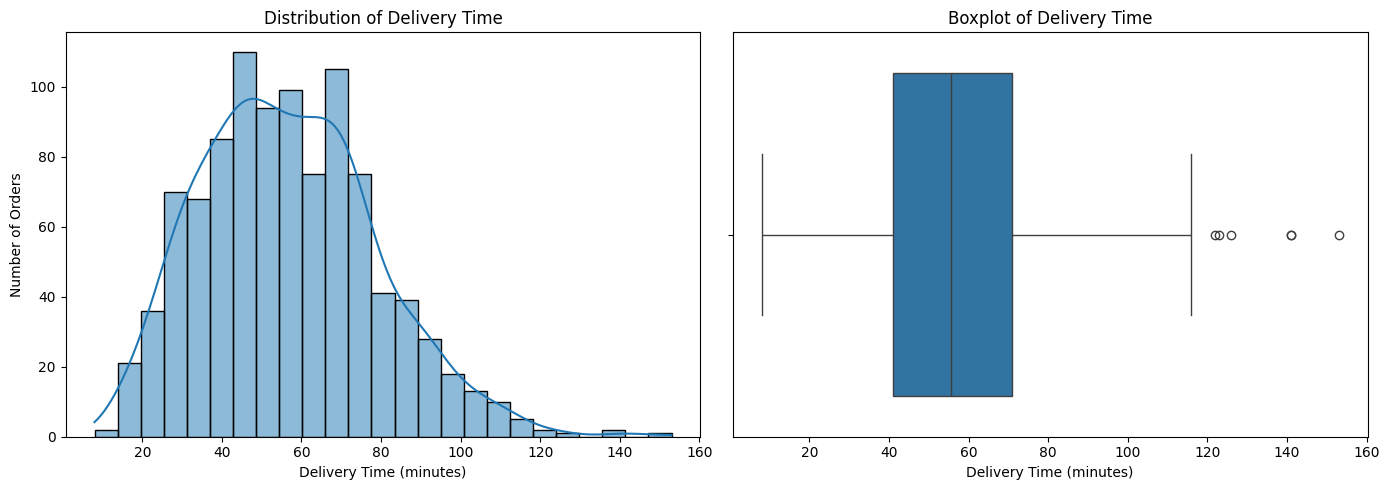

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=df_clean,
    x="Delivery_Time_min",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Delivery Time")
axes[0].set_xlabel("Delivery Time (minutes)")
axes[0].set_ylabel("Number of Orders")

# Boxplot
sns.boxplot(
    data=df_clean,
    x="Delivery_Time_min",
    ax=axes[1]
)
axes[1].set_title("Boxplot of Delivery Time")
axes[1].set_xlabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()


Korelasi jarak dan durasi pengiriman: 0.781


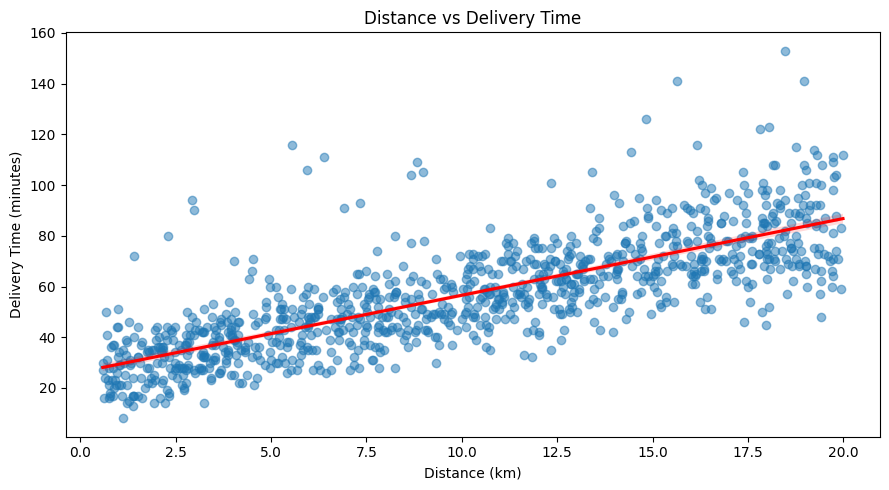

In [ ]:
# Menghitung korelasi Pearson
correlation = df_clean[
    "Distance_km"
].corr(df_clean["Delivery_Time_min"])

print(f"Korelasi jarak dan durasi pengiriman: {correlation:.3f}")

# Membuat scatter plot
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_clean,
    x="Distance_km",
    y="Delivery_Time_min",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.show()


In [ ]:

category_cols = [
    "Weather",
    "Traffic_Level",
    "Time_of_Day",
    "Vehicle_Type"
]

for col in category_cols:
    print(f"\nRata-rata durasi berdasarkan {col}:")
    result = (
        df_clean.groupby(col)["Delivery_Time_min"]
        .agg(["mean", "median", "count"])
        .sort_values("mean", ascending=False)
        .round(2)
    )
    display(result)



Rata-rata durasi berdasarkan Weather:


,mean,median,count
Weather,,,
Snowy,67.11,66.0,97
Rainy,59.79,57.5,204
Foggy,59.47,59.0,103
Windy,55.46,55.0,96
Clear,53.15,52.0,500



Rata-rata durasi berdasarkan Traffic_Level:


,mean,median,count
Traffic_Level,,,
High,64.81,65.0,197
Medium,56.45,54.0,420
Low,52.89,51.0,383



Rata-rata durasi berdasarkan Time_of_Day:


,mean,median,count
Time_of_Day,,,
Evening,57.48,56.0,293
Morning,57.01,56.5,338
Afternoon,56.08,56.0,284
Night,55.21,52.0,85



Rata-rata durasi berdasarkan Vehicle_Type:


,mean,median,count
Vehicle_Type,,,
Car,58.20,56.0,195
Bike,56.57,56.0,503
Scooter,56.05,54.5,302


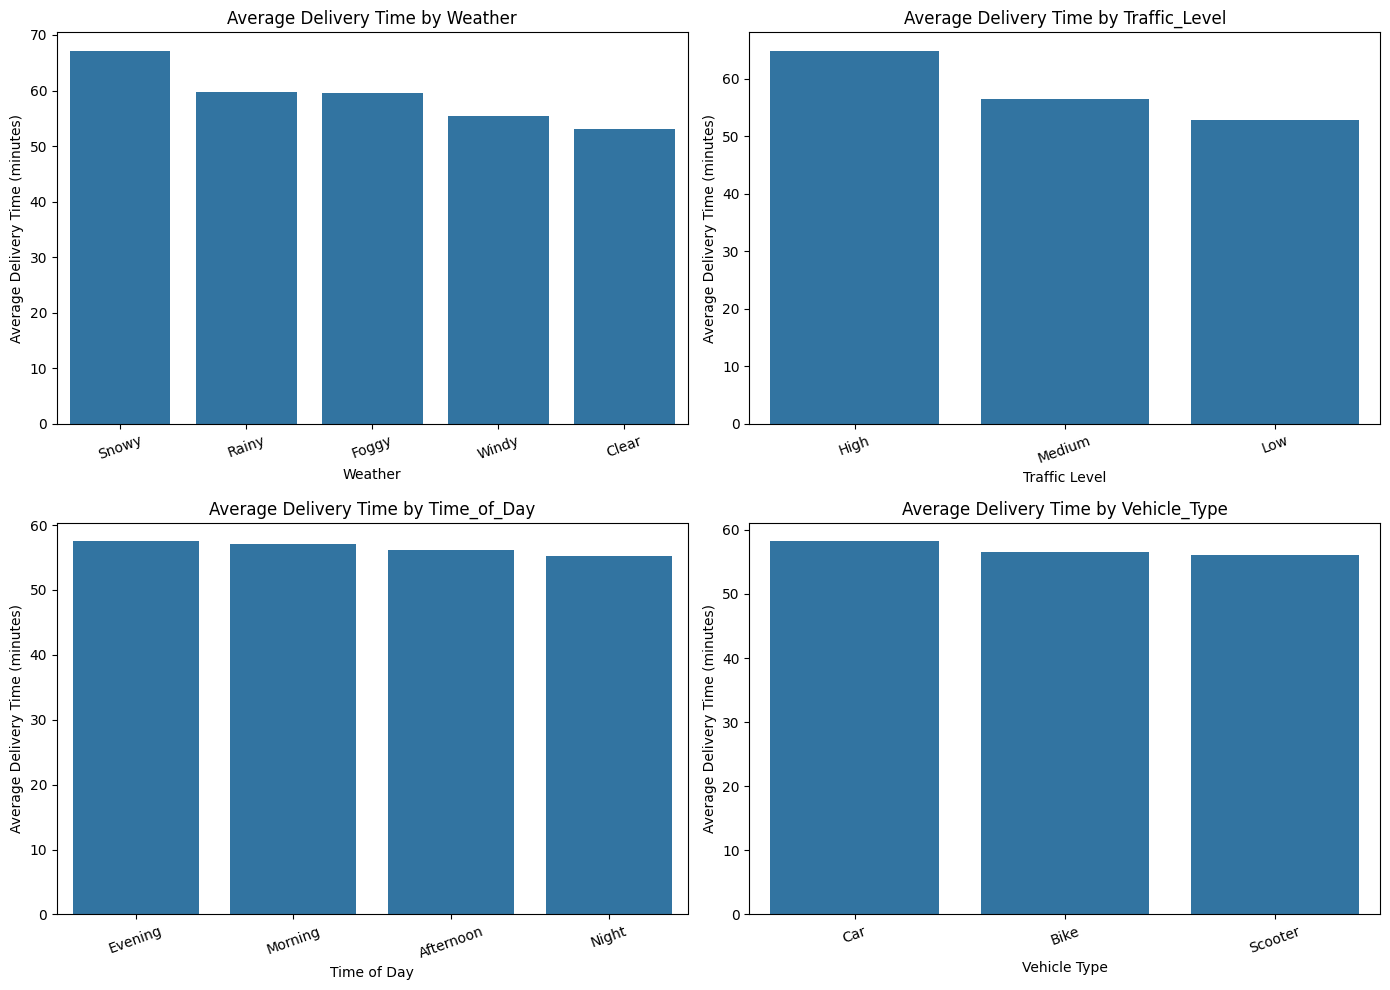

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(category_cols, axes.flatten()):
    order = (
        df_clean.groupby(col)["Delivery_Time_min"]
        .mean()
        .sort_values(ascending=False)
        .index
    )

    sns.barplot(
        data=df_clean,
        x=col,
        y="Delivery_Time_min",
        order=order,
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"Average Delivery Time by {col}")
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel("Average Delivery Time (minutes)")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


Matriks korelasi:


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
Distance_km,1.000,-0.009,-0.008,0.781
Preparation_Time_min,-0.009,1.000,-0.031,0.307
Courier_Experience_yrs,-0.008,-0.031,1.000,-0.089
Delivery_Time_min,0.781,0.307,-0.089,1.000


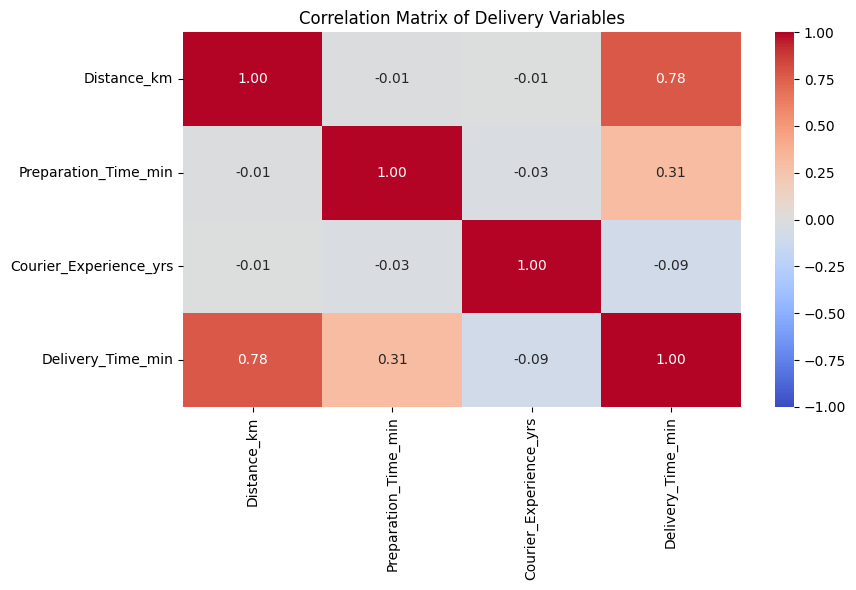

In [ ]:
# Korelasi variabel numerik terhadap durasi pengiriman
numeric_features = [
    "Distance_km",
    "Preparation_Time_min",
    "Courier_Experience_yrs",
    "Delivery_Time_min"
]

correlation_matrix = df_clean[numeric_features].corr()

print("Matriks korelasi:")
display(correlation_matrix.round(3))

# Visualisasi heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix of Delivery Variables")
plt.tight_layout()
plt.show()


In [ ]:
# Analyst-defined delivery time targets
conditions = [
    df['Distance_km'] <= 5,
    (df['Distance_km'] > 5) & (df['Distance_km'] <= 10),
    (df['Distance_km'] > 10) & (df['Distance_km'] <= 15),
    (df['Distance_km'] > 15) & (df['Distance_km'] <= 20)
]

targets = [45, 60, 75, 90]

df['SLA_Target_min'] = np.select(
    conditions,
    targets,
    default=np.nan
)

df['Delivery_Status'] = np.select(
    [
        df['SLA_Target_min'].notna() &
        (df['Delivery_Time_min'] <= df['SLA_Target_min']),

        df['SLA_Target_min'].notna() &
        (df['Delivery_Time_min'] > df['SLA_Target_min'])
    ],
    ['On-Time', 'Late'],
    default='Review Required'
)

# Calculate delay against the assumed target
df['Delay_Minutes'] = (
    df['Delivery_Time_min'] - df['SLA_Target_min']
).where(df['Delivery_Status'] == 'Late')

display(df[[
    'Order_ID', 'Distance_km', 'SLA_Target_min',
    'Delivery_Time_min', 'Delivery_Status', 'Delay_Minutes'
]].head(10))

,Order_ID,Distance_km,SLA_Target_min,Delivery_Time_min,Delivery_Status,Delay_Minutes
0,522,7.93,60.0,43,On-Time,NaN
1,738,16.42,90.0,84,On-Time,NaN
2,741,9.52,60.0,59,On-Time,NaN
3,661,7.44,60.0,37,On-Time,NaN
4,412,19.03,90.0,68,On-Time,NaN
5,679,19.40,90.0,57,On-Time,NaN
6,627,9.52,60.0,49,On-Time,NaN
7,514,17.39,90.0,46,On-Time,NaN
8,860,1.78,45.0,35,On-Time,NaN
9,137,10.62,75.0,73,On-Time,NaN


In [ ]:
valid = df[df['Delivery_Status'].isin(['On-Time', 'Late'])].copy()

total_orders = valid['Order_ID'].nunique()
late_orders = valid.loc[
    valid['Delivery_Status'] == 'Late', 'Order_ID'
].nunique()
on_time_orders = valid.loc[
    valid['Delivery_Status'] == 'On-Time', 'Order_ID'
].nunique()

kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Valid Orders',
        'Late Orders',
        'On-Time Orders',
        'Late Rate (%)',
        'On-Time Rate (%)',
        'Average Delivery Time (min)',
        'Median Delivery Time (min)',
        'Average Distance (km)'
    ],
    'Value': [
        total_orders,
        late_orders,
        on_time_orders,
        late_orders / total_orders * 100 if total_orders else np.nan,
        on_time_orders / total_orders * 100 if total_orders else np.nan,
        valid['Delivery_Time_min'].mean(),
        valid['Delivery_Time_min'].median(),
        valid['Distance_km'].mean()
    ]
})

display(kpi_summary.round(2))

,Metric,Value
0,Total Valid Orders,1000.00
1,Late Orders,158.00
2,On-Time Orders,842.00
3,Late Rate (%),15.80
4,On-Time Rate (%),84.20
5,Average Delivery Time (min),56.73
6,Median Delivery Time (min),55.50
7,Average Distance (km),10.06


In [ ]:
distance_conditions = [
    valid['Distance_km'] <= 5,
    (valid['Distance_km'] > 5) & (valid['Distance_km'] <= 10),
    (valid['Distance_km'] > 10) & (valid['Distance_km'] <= 15),
    (valid['Distance_km'] > 15) & (valid['Distance_km'] <= 20)
]

valid['Distance_Band_Analysis'] = np.select(
    distance_conditions,
    ['0–5 km', '>5–10 km', '>10–15 km', '>15–20 km'],
    default='Outside Target Range'
)

distance_analysis = (
    valid.groupby('Distance_Band_Analysis', observed=True)
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Late_Orders=('Delivery_Status',
                     lambda x: (x == 'Late').sum()),
        Avg_Delivery_Time=('Delivery_Time_min', 'mean'),
        Avg_Target_Time=('SLA_Target_min', 'mean')
    )
    .reset_index()
)

distance_analysis['Late_Rate_pct'] = (
    distance_analysis['Late_Orders'] /
    distance_analysis['Total_Orders'] * 100
).round(2)

display(distance_analysis.round(2))

,Distance_Band_Analysis,Total_Orders,Late_Orders,Avg_Delivery_Time,Avg_Target_Time,Late_Rate_pct
0,0–5 km,248,34,34.33,45.0,13.71
1,>10–15 km,260,37,63.36,75.0,14.23
2,>15–20 km,251,57,79.40,90.0,22.71
3,>5–10 km,241,30,49.03,60.0,12.45


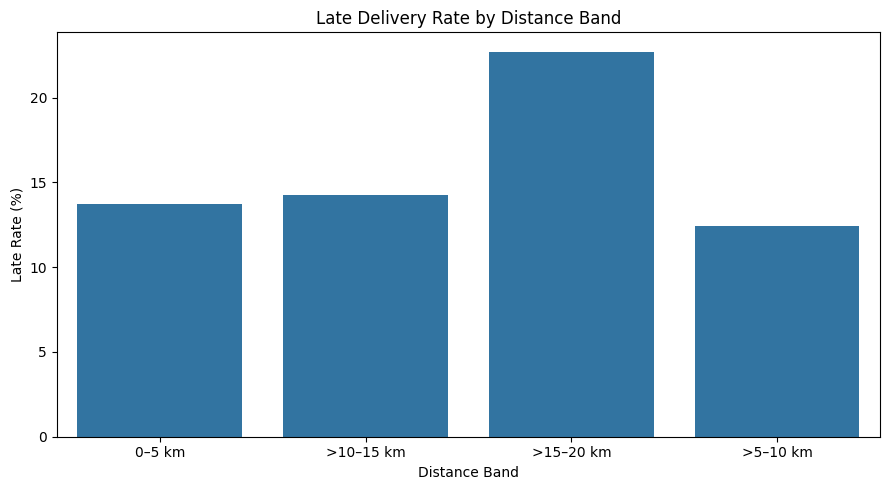

In [ ]:
plot_data = distance_analysis[
    distance_analysis['Distance_Band_Analysis'] != 'Outside Target Range'
]

plt.figure(figsize=(9, 5))
sns.barplot(
    data=plot_data,
    x='Distance_Band_Analysis',
    y='Late_Rate_pct'
)
plt.title('Late Delivery Rate by Distance Band')
plt.xlabel('Distance Band')
plt.ylabel('Late Rate (%)')
plt.tight_layout()
plt.show()

In [ ]:
weather_traffic = (
    valid.groupby(['Weather', 'Traffic_Level'], dropna=False)
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Late_Orders=('Delivery_Status',
                     lambda x: (x == 'Late').sum()),
        Avg_Delivery_Time=('Delivery_Time_min', 'mean')
    )
    .reset_index()
)

weather_traffic['Late_Rate_pct'] = (
    weather_traffic['Late_Orders'] /
    weather_traffic['Total_Orders'] * 100
).round(2)

weather_traffic = weather_traffic.sort_values(
    'Late_Rate_pct', ascending=False
)

display(weather_traffic.round(2))

,Weather,Traffic_Level,Total_Orders,Late_Orders,Avg_Delivery_Time,Late_Rate_pct
11,Rainy,NaN,6,4,64.50,66.67
12,Snowy,High,20,10,70.90,50.00
8,Rainy,High,44,20,77.05,45.45
4,Foggy,High,21,8,67.24,38.10
14,Snowy,Medium,30,11,71.97,36.67
20,NaN,High,6,2,64.83,33.33
19,Windy,NaN,3,1,43.67,33.33
15,Snowy,NaN,3,1,69.33,33.33
6,Foggy,Medium,34,10,64.09,29.41
16,Windy,High,23,6,63.48,26.09


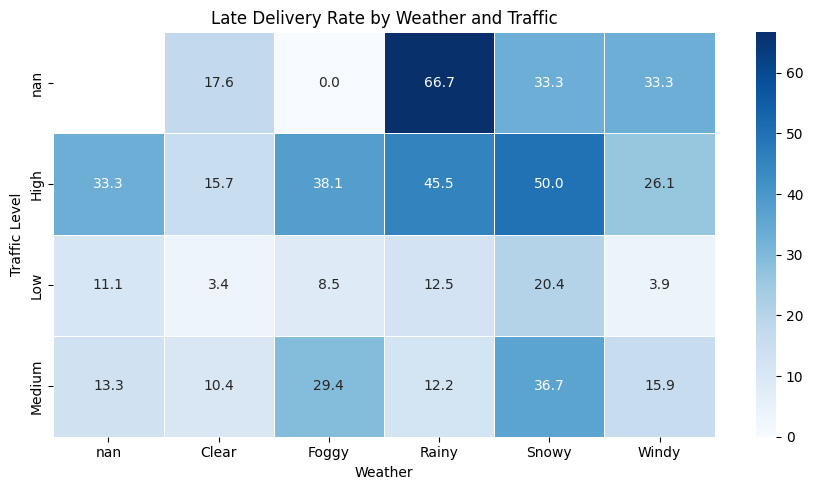

In [ ]:
heatmap_data = weather_traffic.pivot(
    index='Traffic_Level',
    columns='Weather',
    values='Late_Rate_pct'
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5
)
plt.title('Late Delivery Rate by Weather and Traffic')
plt.xlabel('Weather')
plt.ylabel('Traffic Level')
plt.tight_layout()
plt.show()

In [ ]:
status_comparison = (
    valid.groupby('Delivery_Status')
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Avg_Distance_km=('Distance_km', 'mean'),
        Avg_Preparation_min=('Preparation_Time_min', 'mean'),
        Avg_Courier_Experience_yrs=('Courier_Experience_yrs', 'mean'),
        Avg_Delivery_Time_min=('Delivery_Time_min', 'mean')
    )
    .reset_index()
)

display(status_comparison.round(2))

,Delivery_Status,Total_Orders,Avg_Distance_km,Avg_Preparation_min,Avg_Courier_Experience_yrs,Avg_Delivery_Time_min
0,Late,158,11.98,21.85,4.19,83.63
1,On-Time,842,9.70,16.07,4.65,51.68


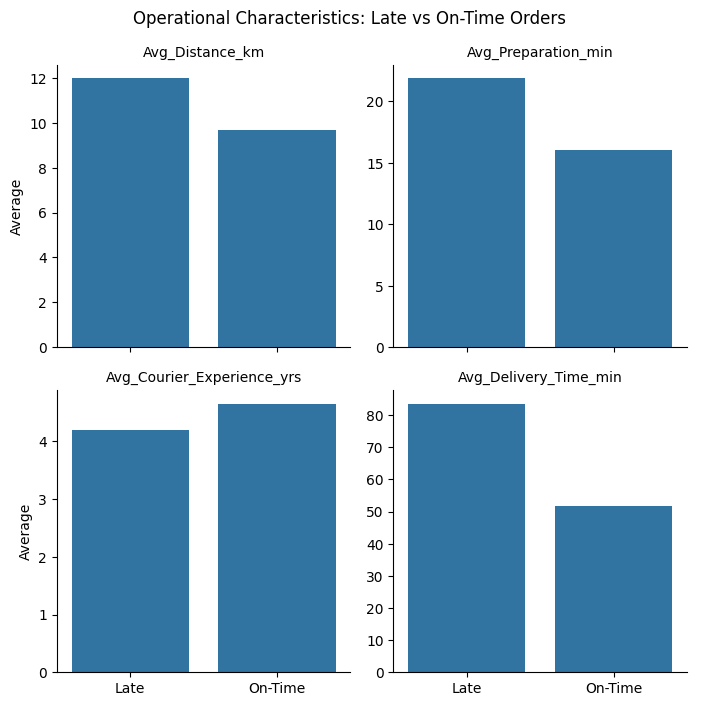

In [ ]:
metrics = [
    'Avg_Distance_km',
    'Avg_Preparation_min',
    'Avg_Courier_Experience_yrs',
    'Avg_Delivery_Time_min'
]

comparison_long = status_comparison.melt(
    id_vars='Delivery_Status',
    value_vars=metrics,
    var_name='Metric',
    value_name='Average'
)

g = sns.catplot(
    data=comparison_long,
    x='Delivery_Status',
    y='Average',
    col='Metric',
    kind='bar',
    col_wrap=2,
    sharey=False,
    height=3.5
)

g.set_titles('{col_name}')
g.set_axis_labels('', 'Average')
g.fig.suptitle(
    'Operational Characteristics: Late vs On-Time Orders',
    y=1.03
)
plt.show()

In [ ]:
EXTREME_THRESHOLD = 116

extreme_orders = df[
    df['Delivery_Time_min'] > EXTREME_THRESHOLD
].copy()

extreme_columns = [
    'Order_ID',
    'Distance_km',
    'Weather',
    'Traffic_Level',
    'Preparation_Time_min',
    'Courier_Experience_yrs',
    'Delivery_Time_min',
    'SLA_Target_min',
    'Delivery_Status'
]

display(
    extreme_orders[extreme_columns]
    .sort_values('Delivery_Time_min', ascending=False)
)

,Order_ID,Distance_km,Weather,Traffic_Level,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,SLA_Target_min,Delivery_Status
379,814,18.46,Clear,NaN,29,1.0,153,90.0,Late
127,446,18.97,Clear,Low,25,4.0,141,90.0,Late
452,394,15.64,Rainy,Low,20,4.0,141,90.0,Late
784,385,14.83,Rainy,Low,19,4.0,126,75.0,Late
29,948,18.05,Clear,Medium,10,7.0,123,90.0,Late
924,428,17.81,Windy,High,21,4.0,122,90.0,Late


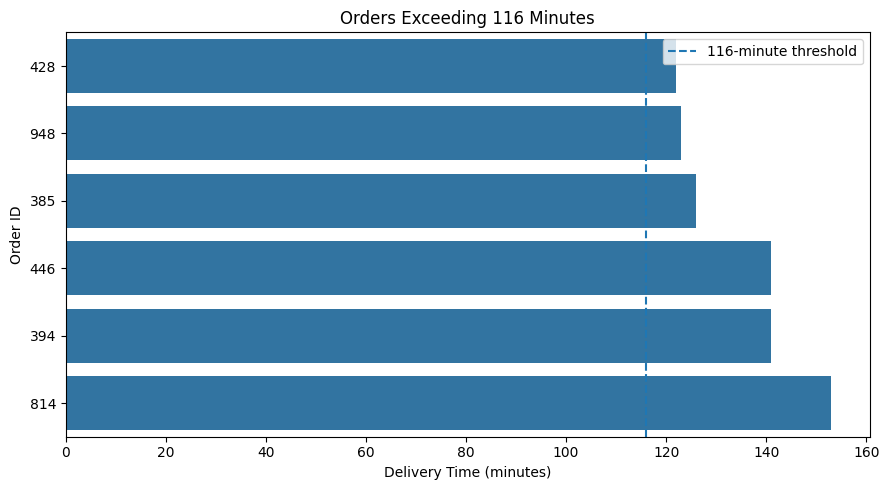

In [ ]:
extreme_plot = extreme_orders.sort_values(
    'Delivery_Time_min', ascending=True
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=extreme_plot,
    x='Delivery_Time_min',
    y=extreme_plot['Order_ID'].astype(str)
)
plt.axvline(
    EXTREME_THRESHOLD,
    linestyle='--',
    label='116-minute threshold'
)
plt.title('Orders Exceeding 116 Minutes')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Order ID')
plt.legend()
plt.tight_layout()
plt.show()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
Distance_km,1.000,-0.009,-0.008,0.781
Preparation_Time_min,-0.009,1.000,-0.031,0.307
Courier_Experience_yrs,-0.008,-0.031,1.000,-0.090
Delivery_Time_min,0.781,0.307,-0.090,1.000


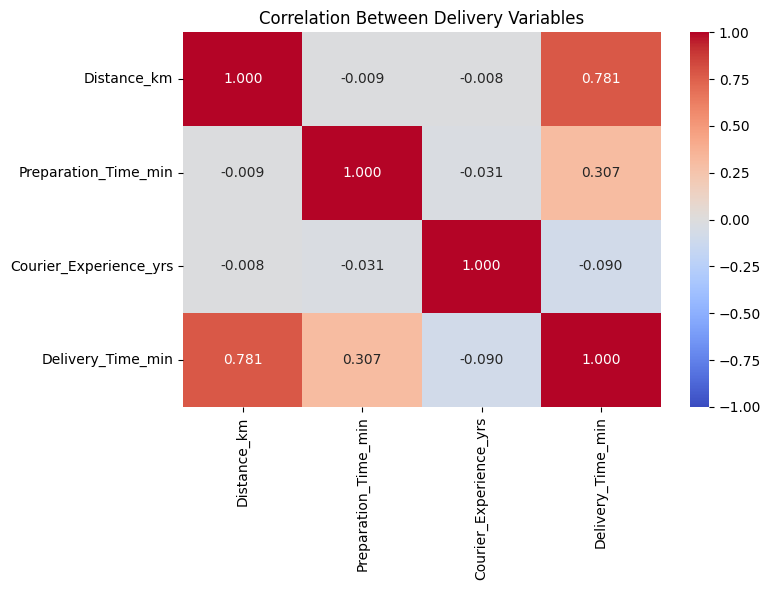

In [ ]:
correlation_columns = [
    'Distance_km',
    'Preparation_Time_min',
    'Courier_Experience_yrs',
    'Delivery_Time_min'
]

correlation_matrix = df[correlation_columns].corr(
    method='pearson'
)

display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Between Delivery Variables')
plt.tight_layout()
plt.show()

In [ ]:
kpi_summary.to_csv(
    'delivery_kpi_summary.csv', index=False
)

distance_analysis.to_csv(
    'delivery_distance_analysis.csv', index=False
)

weather_traffic.to_csv(
    'delivery_weather_traffic_analysis.csv', index=False
)

status_comparison.to_csv(
    'delivery_status_comparison.csv', index=False
)

extreme_orders[extreme_columns].to_csv(
    'extreme_delivery_orders.csv', index=False
)

print("Analysis tables exported successfully.")

Analysis tables exported successfully.


In [ ]:

# Membuat ringkasan insight dari hasil EDA

insights = pd.DataFrame({
    "Faktor": [
        "Jarak pengiriman",
        "Waktu persiapan",
        "Pengalaman kurir",
        "Cuaca",
        "Tingkat kemacetan",
        "Waktu pengiriman",
        "Jenis kendaraan"
    ],
    "Temuan": [
        "Korelasi 0.781",
        "Korelasi 0.307",
        "Korelasi -0.089",
        "Snowy: 67.11 menit; Clear: 53.15 menit",
        "High: 64.81 menit; Low: 52.89 menit",
        "Evening: 57.48 menit; Night: 55.21 menit",
        "Car: 58.20 menit; Scooter: 56.05 menit"
    ],
    "Interpretasi": [
        "Hubungan positif kuat",
        "Hubungan positif sedang",
        "Hubungan negatif sangat lemah",
        "Perbedaan rata-rata cukup besar",
        "Perbedaan rata-rata cukup besar",
        "Perbedaan rata-rata relatif kecil",
        "Perbedaan rata-rata relatif kecil"
    ]
})

display(insights)


,Faktor,Temuan,Interpretasi
0,Jarak pengiriman,Korelasi 0.781,Hubungan positif kuat
1,Waktu persiapan,Korelasi 0.307,Hubungan positif sedang
2,Pengalaman kurir,Korelasi -0.089,Hubungan negatif sangat lemah
3,Cuaca,Snowy: 67.11 menit; Clear: 53.15 menit,Perbedaan rata-rata cukup besar
4,Tingkat kemacetan,High: 64.81 menit; Low: 52.89 menit,Perbedaan rata-rata cukup besar
5,Waktu pengiriman,Evening: 57.48 menit; Night: 55.21 menit,Perbedaan rata-rata relatif kecil
6,Jenis kendaraan,Car: 58.20 menit; Scooter: 56.05 menit,Perbedaan rata-rata relatif kecil


In [ ]:

# Mengekspor dataset yang sudah dibersihkan
output_file = "/content/Food_Delivery_Times_Cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("File berhasil disimpan:", output_file)
print("Ukuran dataset:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())


File berhasil disimpan: /content/Food_Delivery_Times_Cleaned.csv
Ukuran dataset: (1000, 9)
Total missing values: 0


In [ ]:

from google.colab import files

files.download("/content/Food_Delivery_Times_Cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>